# 13 · Why b is hard

**Level:** intermediate · **Prerequisites:** [06](06_marginal_transit_model.ipynb), [12](12_importance_sampling_from_scratch.ipynb) · **Run time:** ~30 s

**Covers:** the shape of the marginal posterior of a transit (the wall at b = 0, the skewed marginal of b, the curved b–a/R★ ridge), a Laplace proposal and how it fails (`pizzetti._sampling.laplace_is`), what MCMC pays for the same shape (autocorrelation times)

With the limb darkening and the baseline integrated out ([06](06_marginal_transit_model.ipynb)), the posterior of a
transit fit lives on five parameters: t0, P, Rp/R★, a/R★ and b. In four of them it is close to Gaussian. The
impact parameter b is the exception, and it decides how hard the posterior is to sample. This notebook looks at
why, and at what goes wrong when importance sampling uses a Gaussian (Laplace) proposal.

In [1]:
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pizzetti
from pizzetti._sampling import laplace_is

SMOKE = os.environ.get("PIZZETTI_SMOKE") == "1"   # shorter runs in the automatic tests
warnings.filterwarnings("ignore", category=RuntimeWarning)

## Data

The hot Jupiter of notebooks 02–06 (7 transits at 2-min cadence), here at b = 0.5 and with 700 ppm noise: a
moderate signal-to-noise ratio, where the posterior of b reaches down to the wall at b = 0.

In [2]:
truth = dict(t0=0.0, per=3.5, rp=0.10, a=9.0, b=0.5, u1=0.40, u2=0.25)
sigma = 700e-6
t_one = np.arange(-0.13, 0.13, 2.0 / 1440)
t = (np.arange(7)[:, None] * truth["per"] + t_one[None, :]).ravel()

p_true = pizzetti.TransitParams()
p_true.t0, p_true.per, p_true.rp, p_true.a = truth["t0"], truth["per"], truth["rp"], truth["a"]
p_true.inc = np.degrees(np.arccos(truth["b"] / truth["a"]))
p_true.ecc, p_true.w, p_true.limb_dark, p_true.u = 0.0, 90.0, "quadratic", [truth["u1"], truth["u2"]]
y = pizzetti.TransitModel(p_true, t).light_curve(p_true) + sigma * np.random.default_rng(42).standard_normal(t.size)

model = pizzetti.MarginalTransitModel(p_true, t, y, sigma, free=["t0", "per", "rp", "a", "b"],
                                      bounds={"rp": (0, 0.5), "a": (1.5, 100)})
print(model.free)

['t0', 'per', 'rp', 'a', 'b']


## The reference posterior

First a converged emcee run on the marginal posterior (as in notebook 06): 32 walkers until the chain is 50
autocorrelation times long and the estimate of τ is stable.

In [3]:
def run_to_convergence(sampler, p0, ntau=(10 if SMOKE else 50), check=500, max_steps=200_000, seed=2024):
    # emcee in chunks of `check` steps until the chain is ntau autocorrelation times long and tau is stable
    sampler.random_state = np.random.RandomState(seed).get_state()
    state, old = p0, np.inf
    while sampler.iteration < max_steps:
        state = sampler.run_mcmc(state, check, progress=False)
        tau = sampler.get_autocorr_time(tol=0)
        if np.all(ntau * tau < sampler.iteration) and np.all(np.abs(old - tau) / tau < 0.01):
            break
        old = tau
    tau = sampler.get_autocorr_time(tol=0)
    return dict(steps=sampler.iteration, tau=tau, burn=int(5 * tau.max()))

nwalkers = 32
x_true = np.array([truth["t0"], truth["per"], truth["rp"], truth["a"], truth["b"]])
p0 = x_true + np.array([2e-4, 2e-6, 1e-3, 0.05, 0.02]) * np.random.default_rng(1).standard_normal((nwalkers, 5))
model.n_eval = 0
sampler = model.EnsembleSampler(nwalkers)
t_start = time.perf_counter()
mc = run_to_convergence(sampler, p0)
wall_mc = time.perf_counter() - t_start
evals_mc = model.n_eval
chain = sampler.get_chain(discard=mc["burn"], flat=True, seed=1)
lab = list(sampler.labels)
ib, ia, ir = lab.index("b"), lab.index("a"), lab.index("rp")
print(f"emcee: {mc['steps']} steps, {evals_mc} evaluations, {wall_mc:.1f} s")
print("autocorrelation times (steps):", {q: int(round(v)) for q, v in zip(model.free, mc["tau"])})

emcee: 15000 steps, 480032 evaluations, 13.7 s
autocorrelation times (steps): {'t0': 67, 'per': 62, 'rp': 117, 'a': 68, 'b': 137}


## Three features of the posterior

1. **A wall at b = 0.** The light curve depends on b only through b² (the sky-projected separation), so the
   likelihood is symmetric about b = 0 and the prior b ≥ 0 cuts it in half. When the data allow small b, the
   posterior is piled up against the wall instead of tapering off.
2. **A skewed marginal of b.** The upper side of the marginal falls steeply (the transit shape fixes the ingress
   duration), the lower side slowly.
3. **A curved ridge.** A larger b with a smaller a/R★ keeps the transit duration fixed, so b and a/R★ are tightly
   and non-linearly related, and so are b and Rp/R★ (limb darkening).

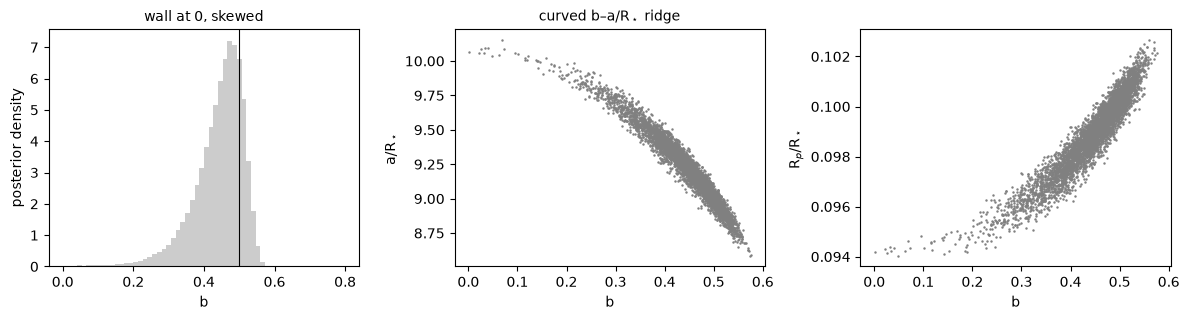

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].hist(chain[:, ib], bins=60, range=(0, 0.8), density=True, histtype="stepfilled", color="0.8")
ax[0].axvline(truth["b"], color="k", lw=0.8)
ax[0].set_xlabel("b"); ax[0].set_ylabel("posterior density"); ax[0].set_title("wall at 0, skewed", fontsize=10)
sel = np.random.default_rng(2).choice(len(chain), min(5000, len(chain)), replace=False)
ax[1].plot(chain[sel, ib], chain[sel, ia], ".", ms=1.5, color="0.5")
ax[1].set_xlabel("b"); ax[1].set_ylabel("a/R$_\\star$"); ax[1].set_title("curved b–a/R$_\\star$ ridge", fontsize=10)
ax[2].plot(chain[sel, ib], chain[sel, ir], ".", ms=1.5, color="0.5")
ax[2].set_xlabel("b"); ax[2].set_ylabel("R$_p$/R$_\\star$")
fig.tight_layout()

## A Laplace proposal

The textbook proposal for importance sampling is the **Laplace approximation**: a (Student-t) distribution
centred on the posterior maximum, with the covariance from the Hessian there. `laplace_is` builds it, draws
from it, and weights the draws with the exact posterior. With `adapt=0` it uses the Laplace proposal as it is.

In [5]:
x0 = model.to_internal(model.fixed_physical_free())[0]
scale = model._default_scales(x0)
L0 = laplace_is(model.log_prob_internal, x0, scale, n=4000, rng=np.random.default_rng(1), adapt=0)
X0, w0 = model.to_physical(L0["theta"]), L0["w"]
print(f"Laplace proposal: k-hat {L0['khat']:.2f}, ESS {L0['ess']:.0f} of 4000")

Laplace proposal: k-hat 0.83, ESS 421 of 4000


k̂ is above 0.7: the Gaussian is too narrow on the long lower side of b, and the few draws there carry large
weights. Here the diagnostic does its job. A natural fix is to **adapt** the proposal: replace its mean and
covariance by those of the weighted draws and draw again (`adapt=3`, until k̂ < 0.5).

In [6]:
L3 = laplace_is(model.log_prob_internal, x0, scale, n=4000, rng=np.random.default_rng(1), adapt=3, khat_target=0.5)
X3, w3 = model.to_physical(L3["theta"]), L3["w"]
for h in L3["history"]:
    print(f"iteration {h['iter']}: k-hat {h['khat']:.2f}, ESS {h['ess']:.0f}")

def tail(Xs, ws, cut=0.15):
    return np.sum(ws[Xs < cut]) / np.sum(ws)

print("\n             emcee   adapted Laplace")
for cut in (0.1, 0.15, 0.2, 0.25):
    print(f"P(b < {cut:4.2f})  {np.mean(chain[:, ib] < cut):.4f}   {tail(X3[:, 4], w3, cut):.4f}")

iteration 0: k-hat 0.83, ESS 421
iteration 1: k-hat 0.74, ESS 1322
iteration 2: k-hat 0.41, ESS 1694

             emcee   adapted Laplace
P(b < 0.10)  0.0030   0.0000
P(b < 0.15)  0.0054   0.0000
P(b < 0.20)  0.0102   0.0000
P(b < 0.25)  0.0207   0.0117


The adapted proposal passes its own check (k̂ < 0.5, a large ESS), and yet it puts almost no weight next to
the wall, where emcee finds a small but real part of the posterior: its tail probabilities fall short by a
growing factor towards b = 0. This is the blind spot of notebook 12: the region
next to the wall is not reachable from the Gaussian's shape, so no draw lands there, and the weights carry no
trace of it. Moment matching cannot fix this either, because a Gaussian in (t0, P, Rp/R★, a/R★, b) cannot
follow a curved ridge into a wall.

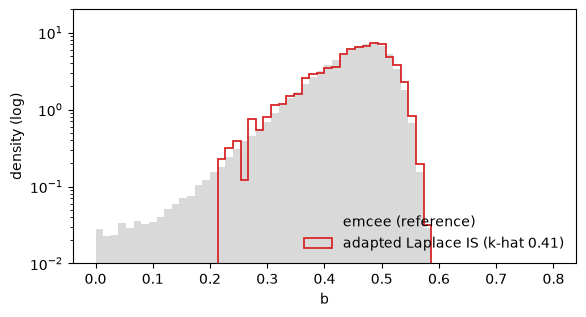

In [7]:
bins = np.linspace(0, 0.8, 61)
plt.figure(figsize=(6.5, 3.3))
plt.hist(chain[:, ib], bins=bins, density=True, histtype="stepfilled", color="0.85", label="emcee (reference)")
plt.hist(X3[:, 4], bins=bins, weights=w3, density=True, histtype="step", color="C3", lw=1.3,
         label=f"adapted Laplace IS (k-hat {L3['khat']:.2f})")
plt.yscale("log"); plt.ylim(1e-2, 20)
plt.xlabel("b"); plt.ylabel("density (log)"); plt.legend(frameon=False);

## What MCMC pays for the same shape

emcee gets the tail right, but slowly. Its autocorrelation time is longest for b and a/R★, the parameters along the
ridge, and it needs about 50 of them for a converged chain:

In [8]:
print(f"longest autocorrelation time: {mc['tau'].max():.0f} steps ({model.free[int(np.argmax(mc['tau']))]})")
print(f"evaluations to convergence:   {evals_mc:,}")
r = model.fit(seed=1)
print(f"fit() (profile IS, notebook 14): {r.diagnostics['khat']:.2f} k-hat, "
      f"P(b < 0.15) {tail(r.weighted_samples[:, r.labels.index('b')], r.weights):.4f}")

longest autocorrelation time: 137 steps (b)
evaluations to convergence:   480,032


fit() (profile IS, notebook 14): 0.10 k-hat, P(b < 0.15) 0.0045


## What you learned

- The posterior of a transit is close to Gaussian except along b: a wall at b = 0, a skewed marginal and a curved
  ridge with a/R★ and Rp/R★.
- A Laplace proposal is too narrow there (k̂ flags it); adapting its moments passes the diagnostics but can still
  miss the part of the posterior next to the wall.
- MCMC gets it right at the cost of long autocorrelation times along the same ridge.

**Next:** [13 · Profile importance sampling step by step](14_profile_importance_sampling.ipynb), a proposal built along b.